# Modulos a utilizar

---

In [ ]:
!pip install numpy pandas scikit-learn plotly scipy


#FASE 1: Comprensión del Negocio
## *Business Understanding*

---

<br>

This dataset is randomly collected from an Iranian telecom companyâ€™s database over a period of 12 months. A total of 3150 rows of data, each representing a customer, bear information for 13 columns. The attributes that are in this dataset
are call failures, frequency of SMS, number of complaints, number of distinct calls, subscription length, age group, the charge amount, type of service, seconds of use, status, frequency of use, and Customer Value.

All of the attributes except for attribute churn is the aggregated data of the first 9 months. The churn labels are the state of the customers at the end of 12 months. The three months is the designated planning gap.



#FASE 2: Comprensión de los Datos
## *Data Understanding*

---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.graph_objects as go
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

In [ ]:
# colors
header_color = '#243B53'
statistic_color = '#E9EFF5'
white = '#FFFFFF'
light_gray = '#F7F9FC'

In [ ]:
# Helpers:
def dataframe_to_table(dataset: pd.DataFrame):
  fg = go.Figure(data = [go.Table(
    header = dict(values= dataset.columns,
                  fill_color=header_color,
                  font=dict(
                      color='white',
                      size=13,
                      family='Arial'
                  ),
                  height=45,
                  align='center'
                  ),

    cells = dict(values = dataset.transpose().values.tolist(),
                 fill_color=statistic_color,
                 font=dict(
                     color='black',
                     size=13,
                     family='Arial'
                 ),
                 height=22,
                 align='center'
                 ))])
  fg.show()


In [ ]:
dataset = pd.read_csv("/content/drive/MyDrive/Elementos de Machine Learning/Projects/datasets/Customer Churn.csv")
dataset.columns = dataset.columns.str.replace(r'\s+', ' ', regex=True).str.strip()
print(f"datos: {dataset.shape[0]}; caracteristicas: {dataset.shape[1]}", "\n")
dataset.info()

datos: 3150; caracteristicas: 14 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call Failure             3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription Length      3150 non-null   int64  
 3   Charge Amount            3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   in

In [ ]:
header_color = '#243B53'
dataframe_to_table(dataset)

In [ ]:
data_matrix = dataset.describe().round(2)

headers = ['Statistic'] + data_matrix.columns.tolist()
cell_values = [data_matrix.index.tolist()] + data_matrix.values.T.tolist()

table = go.Figure( data = [go.Table(
    columnwidth=[100] + [115] * len(data_matrix.columns),
    header=dict(values=headers,
                line_color='darkslategray',
                fill_color=header_color,
                font=dict(
                    color='white',
                    size=13,
                    family='Arial'
                ),
                height=45,
                align='center'),
    cells=dict(values=cell_values,
               line_color='darkslategray',
               fill=dict(color=[statistic_color, light_gray]),
               font=dict(
                   color='black',
                   size=13,
                   family='Arial'),
               height=22,
               align='center'))
])

table.update_layout(width=2000, height=400)
table.show()

- Anonymous Customer ID
- Call Failures: number of call failures
- Complains: binary (0: No complaint, 1: complaint)
- Subscription Length: total months of subscription
- Charge Amount: Ordinal attribute (0: lowest amount, 9: highest amount)
- Seconds of Use: total seconds of calls
- Frequency of use: total number of calls
- Frequency of SMS: total number of text messages
- Distinct Called Numbers: total number of distinct phone calls
- Age Group: ordinal attribute (1: younger age, 5: older age)
- Tariff Plan: binary (1: Pay as you go, 2: contractual)
- Status: binary (1: active, 2: non-active)
- Churn: binary (1: churn, 0: non-churn) - Class label
- Customer Value: The calculated value of customer

In [ ]:
dataset.duplicated().sum()

np.int64(300)

In [ ]:
# Churn = 0: el cliente se quedo
# Churn = 1: el cliente se fue
"""
Para este caso, la variable objetivo de este dataset es la columna Churn
"""

dataset['Churn'].value_counts()

,count
Churn,
0,2655
1,495


In [ ]:
# valores faltantes
missing_values = dataset.isna().sum()
mask = missing_values > 0
result = missing_values[mask].sort_values(ascending=False)
print(result)

Series([], dtype: int64)


- Para este caso no existen valores nulos.

In [ ]:
# porcentajes
churn_counts = dataset['Churn'].value_counts()
total = churn_counts.sum()
porcentages = (churn_counts/ total) * 100
x = ['No Churn (0)', 'Churn (1)']
y = porcentages.round(2)
fig = px.bar(x=x, y=y, title='Porcentaje de Churn', text_auto=True, width=500, height=600)
fig.update_traces(textfont_size=12, textangle=0, textposition="outside", cliponaxis=False)
fig.show()

In [ ]:
# Exploracion de otros datos:
dataset.columns

Index(['Call Failure', 'Complains', 'Subscription Length', 'Charge Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='object')

- Anonymous Customer ID
- Call Failures: number of call failures
- Complains: binary (0: No complaint, 1: complaint)
- Subscription Length: total months of subscription
- Charge Amount: Ordinal attribute (0: lowest amount, 9: highest amount)
- Seconds of Use: total seconds of calls
- Frequency of use: total number of calls
- Frequency of SMS: total number of text messages
- Distinct Called Numbers: total number of distinct phone calls
- Age Group: ordinal attribute (1: younger age, 5: older age)
- Tariff Plan: binary (1: Pay as you go, 2: contractual)
- Status: binary (1: active, 2: non-active)
- Churn: binary (1: churn, 0: non-churn) - Class label
- Customer Value: The calculated value of customer

In [ ]:
# Hacemos una clasificación del tipo de variables.
continuas = ['Call Failure', 'Subscription Length', 'Seconds of Use',
             'Frequency of use', 'Frequency of SMS',
             'Distinct Called Numbers', 'Age', 'Customer Value']

ordinales_categoricas = ['Complains', 'Charge Amount', 'Age Group',
                          'Tariff Plan', 'Status', 'Churn']

In [ ]:
from plotly.subplots import make_subplots
from scipy.stats import gaussian_kde

In [ ]:
# Histogramas
fig = make_subplots(
    rows=3,
    cols=3,
    subplot_titles=continuas
)

for i, col in enumerate(continuas):
    row = i // 3 + 1
    col_pos = i % 3 + 1
    data = dataset[col]

    fig.add_trace(
        go.Histogram(x=data, nbinsx=30, name=col, showlegend=False, opacity=0.75),
        row=row, col=col_pos
    )

    kde = gaussian_kde(data)
    x = np.linspace(data.min(), data.max(), 300)
    y = kde(x)
    bin_width = (data.max() - data.min()) / 30
    y = y * len(data) * bin_width

    fig.add_trace(
        go.Scatter(x=x, y=y, mode='lines', name=f'{col} KDE', showlegend=False),
        row=row, col=col_pos
    )

    fig.update_xaxes(title_text=col, row=row, col=col_pos)
    fig.update_yaxes(title_text='Count', row=row, col=col_pos)

fig.update_layout(
    height=900,
    width=1400,
    title_text="Distribución de variables continuas",
    template="plotly_white",
    bargap=0.05
)

fig.show()

## Analisis de variables:
 - **Call Failure**: La mayoría de clientes tiene 0-2 fallas de llamada. Casi nadie llega a +30. Se puede deducir que las llamadas fallidas es un evento poco comun.
 - **Subscription Length**: La mayor concentracion de suscripcciones de los clientes estan entre 40 y 30 meses según la linea de Gauss. Ademas segun la tabla de estadisticas descriptivas se puede apreciar que la media $(50%)$ estan en 35 meses.
 - **Seconds of Use**: El pico más alto está en 0-2.5k segundos, y luego baja escalonadamente. Ademas, es importante recalcar que la curva no baja suave. Quizas existan subgrupos de distintos clientes.
 - **Frequency of use**: El pico mas alto de llamadas hecha por los clientes estan en el rango 0-70 llamadas. Ademas existe la posibilidad que hayan mas grupos de clientes que hagan entre 150-170 llamadas.
 - **Frequency of SMS**: A comparacion con el otro metodo de comunicacion, que son las llamadas, el mensaje de texto es menor utilizado. Su pico mas alto esta entre 0 y 40 mensajes de texto y despues se vuelve practicamente nulo.
 - **Distinct Called Numbers**: El grueso de los clientes (la mayoría) llama entre 0 y 50 números distintos, con el pico alrededor de 10-20. La grafica esta sesgada a la derecha.
 - **Age**: Para la edad se puede ver algo interesante, existe unos grupos de clientes donde existe entre 20 - 27 años, el siguiente grupo es 27 - 30 años y por ultimo otro grupo entre 42 - 46 años, donde esos grupos son los que mas recurren en las llamadas.
 - **Costumer Value**: El pico dominante está en 0-300: más de la mitad de los clientes tiene un valor calculado bajo. Después cae, pero no de forma suave — hay una jorobita visible alrededor de 750-1000, y el resto se dispersa en una cola larga y delgada hasta 2000+. La curva confirma esto: no es una sola campana decreciente, tiene un segundo "bulto" claramente marcado cerca de 800-900.

In [ ]:
# boxplots
fig = make_subplots(
    rows=3,
    cols=3,
    subplot_titles=continuas
)

for index, col in enumerate(continuas):
  row = index // 3 + 1
  col_pos = index % 3 + 1
  data = dataset[col]

  # px.box returns a Figure object, we need to extract its data (the trace)
  box_trace = px.box(dataset, y=col, title=col).data[0]

  fig.add_trace(
      box_trace,
      row=row, col=col_pos
  )

fig.update_layout(
    height=900,
    width=1400,
    title_text="Diagramas de Box",
    template="plotly_white",
    bargap=0.05
)

fig.show()

In [ ]:
def compute_outliers_iqr(serie: pd.DataFrame) -> dict:
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    RIC = Q3 - Q1

    limite_inf = Q1 - 1.5 * RIC
    limite_sup = Q3 + 1.5 * RIC

    es_outlier = (serie < limite_inf) | (serie > limite_sup)

    return {
        'n_outliers': es_outlier.sum(),
        'pct_outliers': round(es_outlier.mean() * 100, 2),
        'limite_inf': round(limite_inf, 2),
        'limite_sup': round(limite_sup, 2),
    }

resultados = []
for col in continuas:
    stats_outliers = compute_outliers_iqr(dataset[col])
    resultados.append({
        'variable': col,
        'skew': round(dataset[col].skew(), 2),
        **stats_outliers
    })

reporte = pd.DataFrame(resultados).sort_values('skew', ascending=False)
dataframe_to_table(reporte) # imprime la tabla.
dataset[continuas].skew().sort_values(ascending=False)

,0
Frequency of SMS,1.974142
Customer Value,1.427292
Seconds of Use,1.321943
Age,1.248452
Frequency of use,1.144166
Call Failure,1.089752
Distinct Called Numbers,1.029402
Subscription Length,-1.300015


## Relacion entre variables


- El siguiente paso es comprobar la relacion entre las variables, en este paso revisaremos si las otras variables tienen relacion con la variable objetivo.

In [ ]:
from scipy.stats import pointbiserialr, chi2_contingency

resultados_continuas = []
for col in continuas:
    if col == 'Churn':
        continue
    r, p_value = pointbiserialr(dataset['Churn'], dataset[col])
    resultados_continuas.append({
        'variable': col,
        'correlacion': round(r, 3),
        'p_value': round(p_value, 4),
        'significativo': p_value < 0.05
    })

reporte_continuas = pd.DataFrame(resultados_continuas).sort_values(
    'correlacion', key=abs, ascending=False
)

dataframe_to_table(reporte_continuas)

df_corr = pd.DataFrame(resultados_continuas)

# Ordenar por el valor absoluto (impacto real) para que la gráfica tenga un orden lógico
df_corr['Impacto_Absoluto'] = df_corr['correlacion'].abs()
df_corr = df_corr.sort_values('Impacto_Absoluto', ascending=True)


fig = px.bar(
    df_corr,
    x='correlacion',
    y='variable',
    orientation='h',
    color='correlacion',
    color_continuous_scale='RdBu',
    range_color=[-1, 1],
    hover_data=['p_value', 'significativo'],
    title='Correlación de Variables Continuas con Churn (Punto Biserial / Pearson)'
)

fig.update_layout(
    xaxis_title="Coeficiente de Correlación (r)",
    yaxis_title="Variables Continuas",
    coloraxis_colorbar=dict(title="Correlación"),
    height=500
)

fig.add_vline(x=0, line_dash="dash", line_color="gray")
fig.show()

## Correlación Punto Biserial para Análisis de Churn

La Correlación Punto Biserial se utiliza para medir la relación entre una variable **numérica continua** (ej. Factura Mensual, Edad) y una variable **binaria / dicotómica** (ej. Churn: 0 = Se queda, 1 = Se va).

---

## 1. ¿Por qué se usa?
* **Especialización:** La correlación de Pearson tradicional exige que ambas variables sean continuas. Cuando una de ellas es binaria (como el Churn), el método matemático correcto y preciso para evaluar la relación es el Punto Biserial.
* **Aporte clave (El p-value):** A diferencia de un simple cálculo de correlación en Pandas (`df.corr()`), este método calcula la **significancia estadística**, asegurando que las conclusiones no sean fruto del azar o del ruido en los datos.

---

## 2. ¿Qué es exactamente?
Matemáticamente, equivale a calcular el coeficiente de Pearson entre una columna de números y una columna de ceros y unos. Genera dos métricas fundamentales que se deben evaluar en orden:
1. **`p-value` (Valor de p):** Determina si la relación es real o casualidad.
2. **`r` (Coeficiente):** Determina la fuerza y dirección de la relación (va de -1 a 1).

---

## 3. Patrón de Interpretación (El algoritmo de decisión)

Para saber si una variable influye o no en el Churn, sigue este orden:

### PASO 1: Filtrar por Significancia (`p-value`)
El `p-value` es el interruptor de validez (límite estándar: **0.05**):
* 🟢 **Si `p_value < 0.05`:** La relación **SÍ es significativa**. El resultado es confiable.
* 🔴 **Si `p_value >= 0.05`:** La relación **NO es significativa**. **Ignora esta variable.**

### PASO 2: Evaluar la Dirección y Fuerza (`r`)
Solo si la variable superó el PASO 1, analiza el valor de `r`:

* **`r` Positivo (Cercano a +1):** Relación directa.
  * *Patrón:* A **mayor** valor numérico de la variable, **más probabilidad** de que el cliente cancele el servicio (`Churn = 1`).
* **`r` Negativo (Cercano a -1):** Relación inversa.
  * *Patrón:* A **mayor** valor numérico de la variable, **menos probabilidad** de que el cliente cancele (tiende a quedarse, `Churn = 0`).
* **`r` Cercano a 0 (ej. 0.05 o -0.05):** Relación débil.
  * *Patrón:* Aunque sea estadísticamente válida, el impacto real de esta variable sobre la decisión del cliente es insignificante.


## Relación entre Variables Categóricas (Chi-cuadrado)

Para analizar la relación entre dos variables categóricas, como 'Churn' y 'Complains' (ambas binarias en este caso), la prueba de Chi-cuadrado de independencia es la herramienta estadística adecuada.

La prueba de Chi-cuadrado nos ayuda a determinar si existe una asociación significativa entre las dos variables. Se basa en comparar las frecuencias observadas en una tabla de contingencia con las frecuencias esperadas si las variables fueran completamente independientes.

### Interpretación de los Resultados:

*   **Estadístico Chi-cuadrado:** Un valor más alto indica una mayor diferencia entre las frecuencias observadas y esperadas, sugiriendo una posible relación.
*   **Valor p (p-value):** Es el indicador clave de significancia estadística.
    *   **Si p-value < 0.05 (umbral común):** Se rechaza la hipótesis nula de independencia. Esto significa que hay una **asociación estadísticamente significativa** entre las dos variables.
    *   **Si p-value >= 0.05:** No se puede rechazar la hipótesis nula. Esto sugiere que no hay una evidencia estadística suficiente para afirmar que existe una asociación entre las variables.

In [ ]:
from scipy.stats import chi2_contingency

# Aplicamos la prueba de Chi-cuadrado a Churn vs Complains y Churn vs Age_group
tabla_contingencia_com = pd.crosstab(dataset['Churn'], dataset['Complains'])
tabla_contingencia_age = pd.crosstab(dataset['Churn'], dataset['Age Group'])
tabla_contingencia_status = pd.crosstab(dataset['Churn'], dataset['Status'])


# Realizar la prueba dem Chi-cuadrado
chi2, p_value, dof, expected = chi2_contingency(tabla_contingencia_com)
chi2_age, p_value_age, dof_age, expected_age = chi2_contingency(tabla_contingencia_age)
chi2_status, p_value_status, dof_status, expected_status = chi2_contingency(tabla_contingencia_status)

# Resultados de Churn
print(f"Tabla de Contingencia:\n{tabla_contingencia_com}")
print(f"\nEstadístico Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p_value:.4f}")
print(f"Grados de libertad: {dof}")

if p_value < 0.05:
    print("\nConclusión: Existe una asociación estadísticamente significativa entre 'Churn' y 'Complains'.")
else:
    print("\nConclusión: No hay una asociación estadísticamente significativa entre 'Churn' y 'Complains'.")


print()

# Resultados de Age Group
print(f"Tabla de Contingencia 'Churn' vs 'Age Group':\n{tabla_contingencia_age}")
print(f"\nEstadístico Chi-cuadrado: {chi2_age:.4f}")
print(f"Valor p: {p_value_age:.4f}")
print(f"Grados de libertad: {dof_age}")

if p_value_age < 0.05:
    print("\nConclusión: Existe una asociación estadísticamente significativa entre 'Churn' y 'Age Group'.")
else:
    print("\nConclusión: No hay una asociación estadísticamente significativa entre 'Churn' y 'Age Group'.")


Tabla de Contingencia:
Complains     0    1
Churn               
0          2614   41
1           295  200

Estadístico Chi-cuadrado: 886.2116
Valor p: 0.0000
Grados de libertad: 1

Conclusión: Existe una asociación estadísticamente significativa entre 'Churn' y 'Complains'.

Tabla de Contingencia 'Churn' vs 'Age Group':
Age Group    1    2     3    4    5
Churn                              
0          123  853  1195  316  168
1            0  184   230   79    2

Estadístico Chi-cuadrado: 58.9559
Valor p: 0.0000
Grados de libertad: 4

Conclusión: Existe una asociación estadísticamente significativa entre 'Churn' y 'Age Group'.


In [ ]:
# Verificación de leakage: Status vs Churn
tasa_churn_por_status = dataset.groupby('Status')['Churn'].mean() * 100
print(tasa_churn_por_status)

Status
1     5.278716
2    47.314578
Name: Churn, dtype: float64


Se excluyó Status por riesgo de fuga de información (data leakage): la tasa de churn es 9 veces mayor en clientes inactivos (47.3%) que en activos (5.3%), lo que sugiere que ambas variables capturan prácticamente el mismo evento en momentos distintos, no una relación predictiva genuina.

#FASE 3: Preparación de los Datos
## *Data Preparation*
---

In [ ]:
RANDOM_STATE = 42
# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Las 3 técnicas
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight

In [ ]:
# Creamos un dataset sin las variables que no tiene ninguna relacion con la variable obejtivo.
dataset_model = dataset.drop(["Subscription Length", "Age", "Call Failure", "Charge Amount", "Tariff Plan", "Status"], axis=1) # axis = 1 para columnas
dataset_model.columns

Index(['Complains', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Customer Value', 'Churn'],
      dtype='object')

**Hay algo importante por revisar en todo análisis exploratorio: la redundancia entre variables. Esto ocurre cuando dos o más características miden, en esencia, lo mismo — es decir, están altamente correlacionadas entre sí, no solo con la variable objetivo. Detectar estos casos es clave antes de modelar, porque mantener variables redundantes no aporta información nueva al modelo y puede distorsionar su interpretación.**

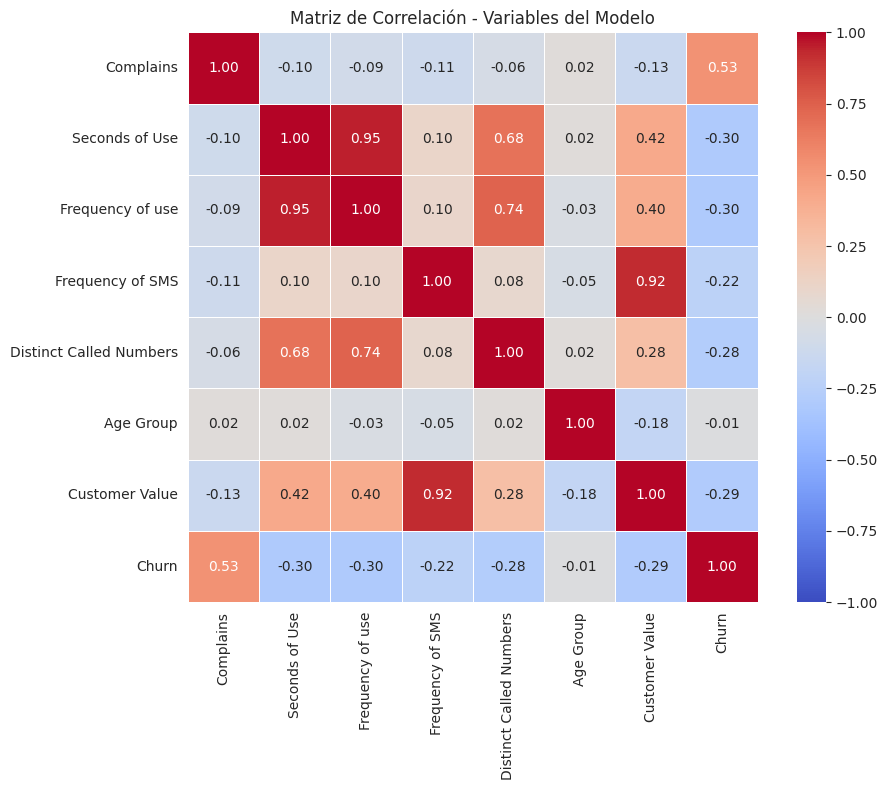

In [ ]:
plt.figure(figsize=(10, 8))

matriz_corr = dataset_model.corr()

sns.heatmap(
    matriz_corr,
    annot=True,        # muestra el número de cada celda
    fmt=".2f",          # 2 decimales
    cmap="coolwarm",    # rojo = positiva, azul = negativa
    vmin=-1, vmax=1,    # fija la escala de color entre -1 y 1
    linewidths=0.5,
    square=True
)

plt.title("Matriz de Correlación - Variables del Modelo")
plt.tight_layout()
plt.show()

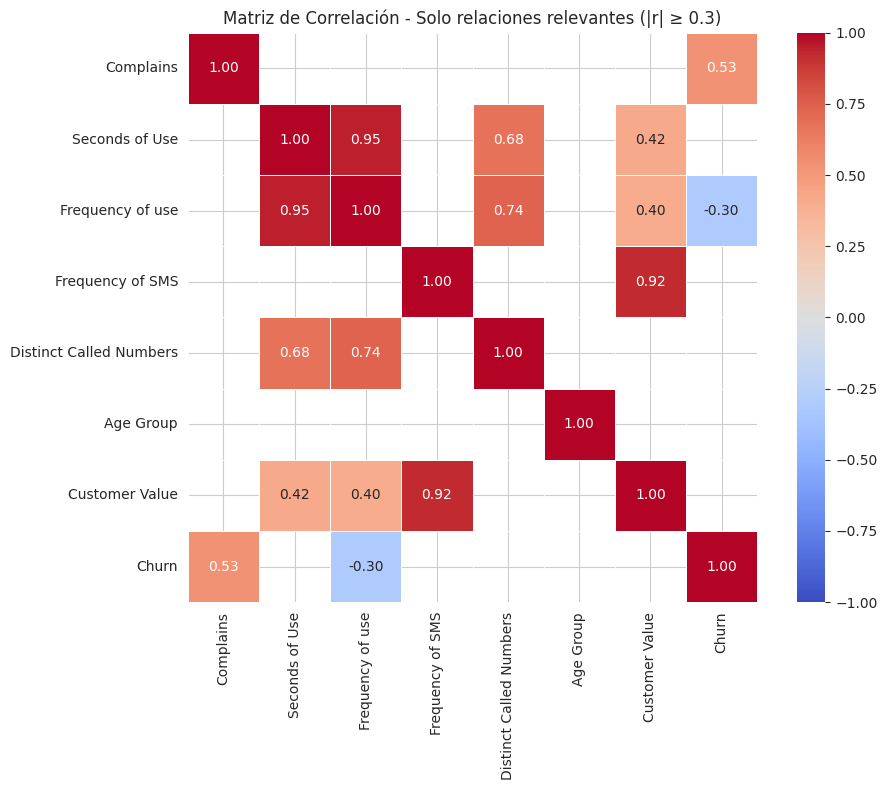

In [ ]:
plt.figure(figsize=(10, 8))

mascara = np.abs(matriz_corr) < 0.3  # oculta correlaciones débiles (ruido visual)

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    mask=mascara,
    linewidths=0.5,
    square=True
)

plt.title("Matriz de Correlación - Solo relaciones relevantes (|r| ≥ 0.3)")
plt.tight_layout()
plt.show()

In [ ]:
dataset_model = dataset.drop(["Subscription Length", "Age", "Call Failure", "Charge Amount", "Tariff Plan", "Status", "Customer Value", "Frequency of use"], axis=1) # axis = 1 para columnas
dataset_model.columns

Index(['Complains', 'Seconds of Use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Churn'],
      dtype='object')

Aquí tienes un texto corto para pegar como celda markdown:

> Se eliminaron `Customer Value` y `Frequency of use` por redundancia (multicolinealidad): `Customer Value` correlaciona 0.92 con `Frequency of SMS`, y `Frequency of use` correlaciona 0.95 con `Seconds of Use`. Mantener ambos pares aportaría la misma información dos veces, sin ganancia real para el modelo, y distorsionaría la interpretación de los coeficientes en la regresión logística. Se conservó la variable más directa e interpretable de cada par (`Frequency of SMS` y `Seconds of Use`), simplificando el dataset de 8 a 6 columnas sin perder poder predictivo.

In [ ]:
# Para las tecnicas, debemos crear una variable X sin la variable objetivo.
X = dataset_model.drop('Churn', axis=1)
y = dataset_model['Churn']

In [ ]:
# separamos los datos, recordar que con el test_size = 0.2 se refiere que 20 % de test y 80% para train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,stratify=y, random_state=RANDOM_STATE)

print(f"X train = {X_train.shape}")
print(f"X test = {X_test.shape}")
print(f"y train = {y_train.shape}")
print(f"y test = {y_test.shape}")

X train = (2520, 5)
X test = (630, 5)
y train = (2520,)
y test = (630,)


In [ ]:
cols_log = ['Seconds of Use', 'Frequency of SMS']
for col in cols_log:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

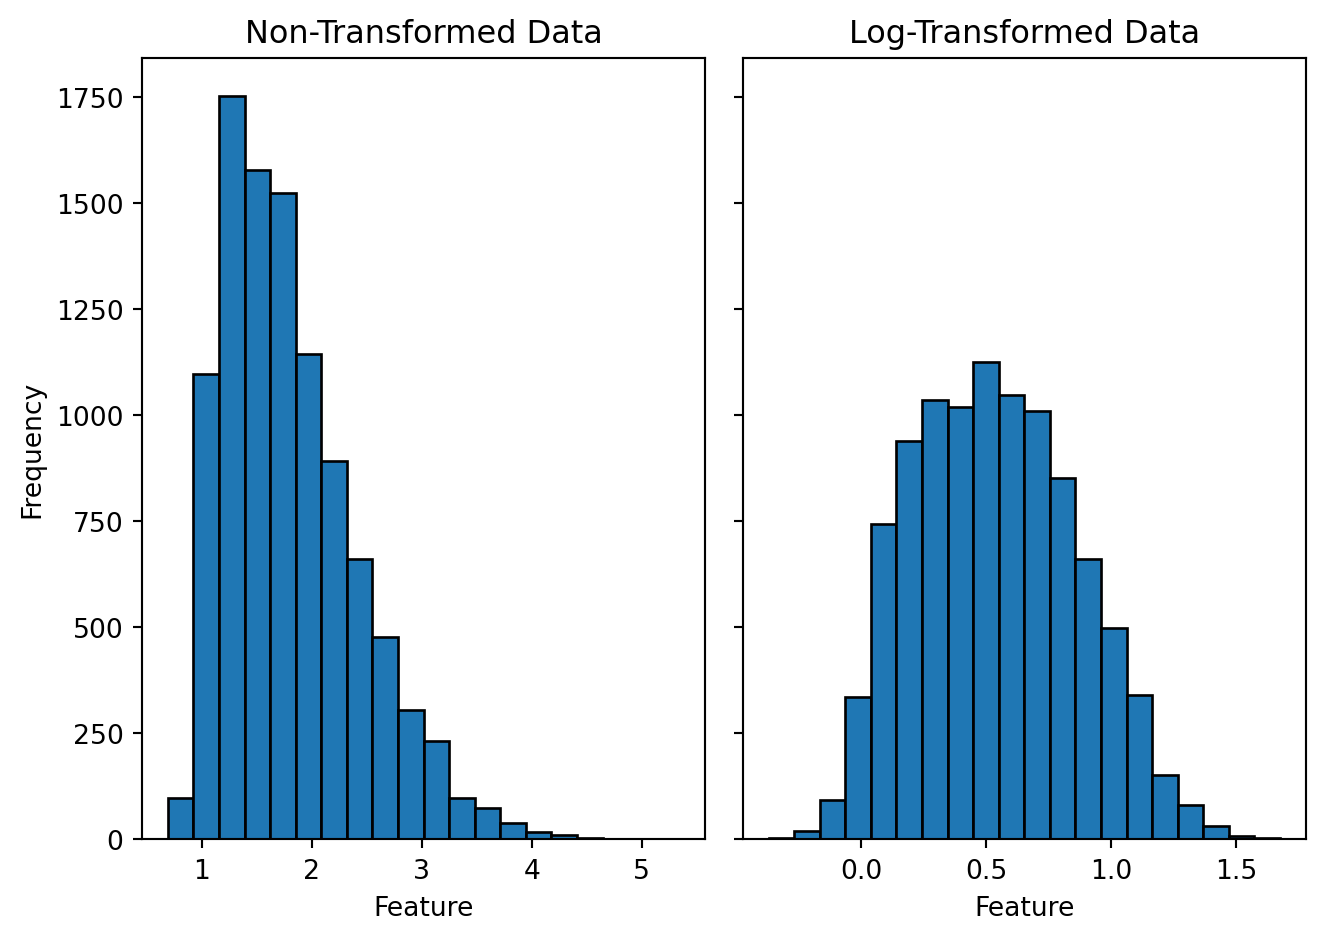

#FASE 4: Modelado
## *Modeling*

---

## Arbol de desición

In [ ]:
tree = DecisionTreeClassifier(
    max_depth=4,            # límite de profundidad, para evitar sobreajuste y poder visualizarlo
    class_weight='balanced', # compensa el desbalance de clases
    random_state=RANDOM_STATE
)

tree.fit(X_train_scaled, y_train)  # el árbol no necesita datos escalados
y_pred_arbol = tree.predict(X_test_scaled)

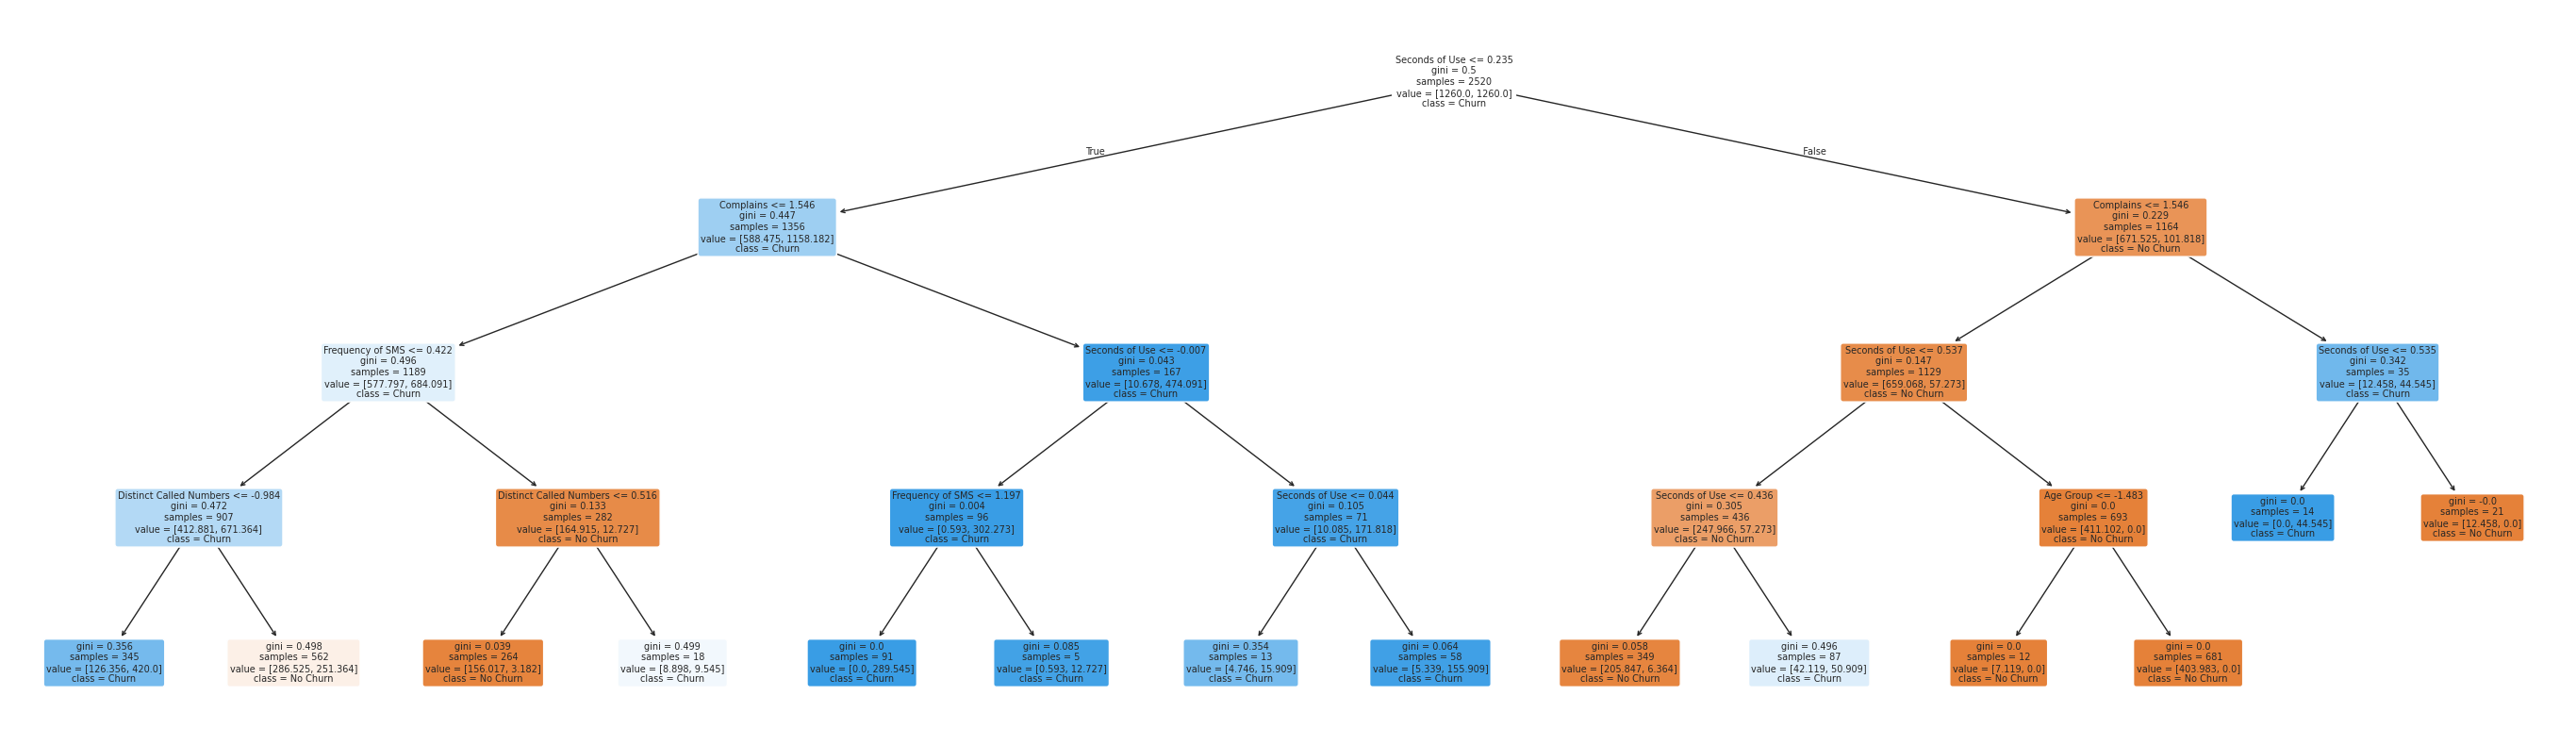

In [ ]:
plt.figure(figsize=(35, 10))
plot_tree(
    tree,
    feature_names=X_train.columns,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.show()

## Regresión logistica

In [ ]:
logreg = LogisticRegression(
    class_weight='balanced',  # mismo motivo que en el árbol: compensa el desbalance
    random_state=RANDOM_STATE,
    max_iter=100000          # a veces necesita más iteraciones para converger
)

logreg.fit(X_train_scaled, y_train)
y_pred_logreg = logreg.predict(X_test_scaled)

In [ ]:
coeficientes = pd.DataFrame({
    'variable': X_train.columns,
    'coeficiente': logreg.coef_[0]
}).sort_values('coeficiente', key=abs, ascending=False)

print(coeficientes)

                  variable  coeficiente
0                Complains     1.130320
3  Distinct Called Numbers    -0.966663
1           Seconds of Use    -0.446598
2         Frequency of SMS    -0.360025
4                Age Group    -0.012448


## Perceptron Multi capa

In [ ]:
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    max_iter=1000,
    early_stopping=True,
    random_state=RANDOM_STATE,
)

mlp.fit(X_train_scaled, y_train)
y_pred_mlp = mlp.predict(X_test_scaled)

#FASE 5: Evaluación
## *Evaluation*

---

In [ ]:
# Evaluación
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, classification_report,
                             f1_score)

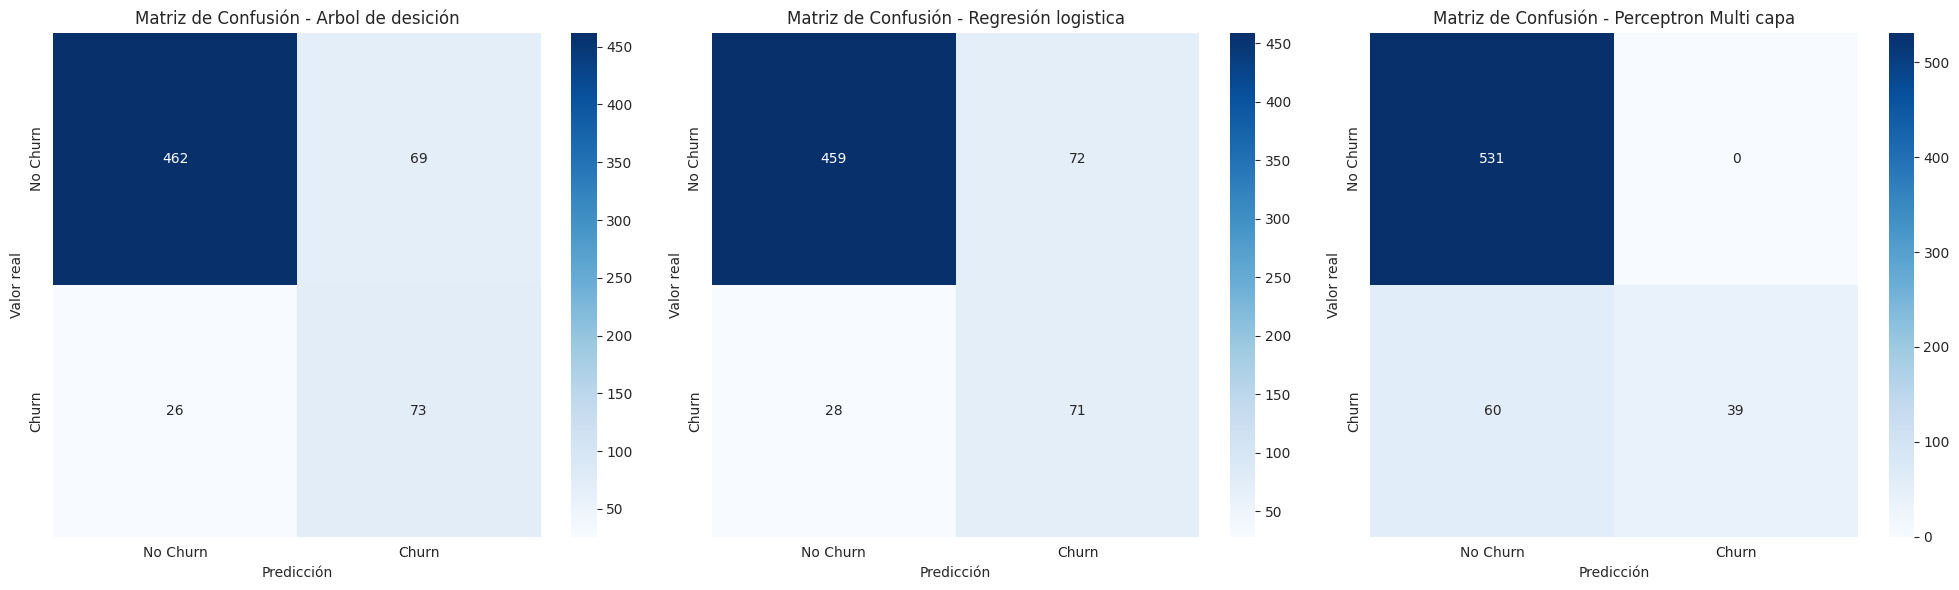

In [ ]:
models = {
    "Arbol de desición": y_pred_arbol,
    "Regresión logistica": y_pred_logreg,
    "Perceptron Multi capa": y_pred_mlp
}

results = []

# Create a figure with subplots for the confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes = axes.flatten() # Flatten in case of multiple rows/columns

for i, (model_name, y_pred) in enumerate(models.items()):
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=axes[i] # Plot on the current subplot
    )
    axes[i].set_title(f"Matriz de Confusión - {model_name}")
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor real")

    results.append({
        "Modelo": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1
    })

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
dataframe_to_table(results_df)

# Conclusiones

De los tres modelos evaluados, el árbol de decisión obtuvo el mejor F1-score (0.61), con el mejor balance entre detectar clientes en riesgo de churn (recall 73.7%) y no generar demasiadas falsas alarmas. Además, es el más interpretable: sus reglas de decisión pueden explicarse directamente al negocio.

El perceptrón multicapa tuvo el accuracy más alto (90.5%), pero esta cifra es engañosa: su recall de solo 39.4% significa que deja pasar a 6 de cada 10 clientes que realmente se iban a ir. Esto confirma por qué el accuracy no es una métrica confiable cuando las clases están desbalanceadas (solo 15.7% de los clientes hicieron churn) — un modelo puede parecer "mejor" simplemente por predecir la clase mayoritaria con más frecuencia.

La regresión logística tuvo un desempeño muy similar al árbol, lo cual sugiere que la relación entre las variables seleccionadas y el churn es, en gran parte, lineal y puede explicarse sin necesidad de modelos más complejos.

Recomendación: para este problema, priorizar el recall sobre el accuracy tiene sentido de negocio — el costo de no detectar a un cliente que se va (perderlo por completo) suele ser mayor que el costo de ofrecer una retención innecesaria a alguien que se iba a quedar. Por eso, el árbol de decisión es el modelo recomendado: buen equilibrio, e interpretable para justificar decisiones de retención ante el negocio.

Limitaciones y trabajo futuro: se detectó y corrigió multicolinealidad entre variables (Customer Value con Frequency of SMS, y Frequency of use con Seconds of Use), lo que mejoró la calidad del dataset de entrada. Queda pendiente explorar técnicas de balanceo de clases más allá del class_weight (como oversampling) y un análisis de clustering no supervisado para identificar segmentos de clientes de riesgo.

# Bibliografia

Iranian Churn [Dataset]. (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5JW3Z.

GeeksforGeeks. (2026, June 22). Exploratory data analysis. GeeksforGeeks. https://www.geeksforgeeks.org/data-analysis/what-is-exploratory-data-analysis/


Learn Python, Data Viz, Pandas & more | Tutorials | Kaggle. (n.d.). https://www.kaggle.com/learn